# Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2  
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
- **Equipe**:
  - Izabella de Lima Catrinck
  - Vinícius Castro Coutinho

## Explorando uma base de dados

Nesta atividade prática iremos explorar a seguinte base de dados **_Dry Bean Dataset_**

1. Obtenha esta base de dados no seguinte link: https://archive.ics.uci.edu/dataset/602/dry+bean
2. Consulte a documentação oficial da base de dados: https://archive.ics.uci.edu/dataset/602/dry+bean e o artigo de origem: https://doi.org/10.1016/j.compag.2020.105507
3. **Responda**:  
    3.1 O que é cada exemplo na base de dados?  
    3.2 Em que ano ela foi obtida?  
    3.3 Quem foram os responsáveis pela criação desta base de dados?

In [1]:
## Reservado para a importação de bibliotecas
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# fetch dataset
dry_bean = fetch_ucirepo(id=602)

### 3.1

In [3]:
assert "instances_represent" in dry_bean.metadata.additional_info.keys()

print(dry_bean.metadata.additional_info["instances_represent"])

None


In [4]:
# instances_represent is None
dry_bean.metadata.additional_info["summary"]

'Seven different types of dry beans were used in this research, taking into account the features such as form, shape, type, and structure by the market situation. A computer vision system was developed to distinguish seven different registered varieties of dry beans with similar features in order to obtain uniform seed classification. For the classification model, images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. Bean images obtained by computer vision system were subjected to segmentation and feature extraction stages, and a total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.'

Do sumário: cada exemplo representa as características de um grão de feijão de um dentre sete tipos de feijão obtidas a partir da imagem do grão, usando um sistema de visão computacional.

### 3.2

In [5]:
print(dry_bean.metadata.year_of_dataset_creation)

2020


2020

### 3.3

In [6]:
print(dry_bean.metadata.creators)

[]


Do artigo: M. Koklu, Ilker Ali Özkan.

## Manipulando a base de dados

1. Abra a base de dados com o pandas
2. Imprima os 10 primeiros exemplos pertencentes à esta base
3. Imprima os 10 últimos exemplos pertencentes à esta base
4. Quantos exemplos esta base de dados possui?
5. Quais são os atributos que a base de dados possui e quais seus tipos?
6. Há algum dado faltante na base?
7. De acordo com a documentação da base de dados, qual o significado do atributo "Class"?  
  7.1 Este atributo é quantitativo ou qualitativo?  
  7.2 Qual o tipo de codificação utilizada para denotar este atributo na base original? Que codificação você aplicaria antes de treinar uma rede neural? Consulte a seguinte referência: https://pbpython.com/categorical-encoding.html

In [7]:
# 1
df = dry_bean.data.original

In [8]:
# 2
df.head(10)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
5,30279,634.927,212.560556,181.510182,1.171067,0.520401,30600,196.347702,0.775688,0.989510,0.943852,0.923726,0.007020,0.003153,0.853270,0.999236,SEKER
6,30477,670.033,211.050155,184.039050,1.146768,0.489478,30970,196.988633,0.762402,0.984081,0.853080,0.933374,0.006925,0.003242,0.871186,0.999049,SEKER
7,30519,629.727,212.996755,182.737204,1.165591,0.513760,30847,197.124320,0.770682,0.989367,0.967109,0.925480,0.006979,0.003158,0.856514,0.998345,SEKER
8,30685,635.681,213.534145,183.157146,1.165852,0.514081,31044,197.659696,0.771561,0.988436,0.954240,0.925658,0.006959,0.003152,0.856844,0.998953,SEKER
9,30834,631.934,217.227813,180.897469,1.200834,0.553642,31120,198.139012,0.783683,0.990810,0.970278,0.912125,0.007045,0.003008,0.831973,0.999061,SEKER


In [9]:
# 3
df.tail(10)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13601,42042,771.515,288.082674,186.347090,1.545947,0.762615,42476,231.364511,0.816254,0.989782,0.887574,0.803118,0.006852,0.001758,0.644999,0.997134,DERMASON
13602,42047,768.936,292.975007,183.139141,1.599740,0.780543,42446,231.378268,0.773890,0.990600,0.893644,0.789754,0.006968,0.001672,0.623712,0.997777,DERMASON
13603,42049,770.185,290.163403,185.051685,1.568013,0.770243,42503,231.383771,0.756005,0.989318,0.890790,0.797426,0.006901,0.001721,0.635888,0.997080,DERMASON
13604,42070,763.489,289.022373,186.123434,1.552853,0.765046,42556,231.441543,0.768823,0.988580,0.906936,0.800774,0.006870,0.001743,0.641239,0.995750,DERMASON
13605,42070,760.701,276.691651,193.945367,1.426647,0.713216,42458,231.441543,0.730813,0.990862,0.913596,0.836460,0.006577,0.001986,0.699666,0.998176,DERMASON
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [10]:
# 4
print(df.shape[0], "exemplos.")

13611 exemplos.


In [11]:
# 5
dry_bean.variables[["name", "type"]]

,name,type
0,Area,Integer
1,Perimeter,Continuous
2,MajorAxisLength,Continuous
3,MinorAxisLength,Continuous
4,AspectRatio,Continuous
5,Eccentricity,Continuous
6,ConvexArea,Integer
7,EquivDiameter,Continuous
8,Extent,Continuous
9,Solidity,Continuous


In [12]:
# 6
if "yes" in list(dry_bean.variables.missing_values):
  print("Há valores faltantes.")
else:
  print("Não há valores faltantes.")
dry_bean.variables.missing_values

Não há valores faltantes.


,missing_values
0,no
1,no
2,no
3,no
4,no
5,no
6,no
7,no
8,no
9,no


In [13]:
# 7
print("É o tipo de feijão.")
list(dry_bean.variables[dry_bean.variables["name"] == "Class"]["description"])[0]

É o tipo de feijão.


'(Seker, Barbunya, Bombay, Cali, Dermosan, Horoz and Sira)'

In [14]:
# 7.1
print("É um atributo qualitativo.")
dry_bean.variables.loc[dry_bean.variables["name"] == "Class"][["name", "type"]]

É um atributo qualitativo.


,name,type
16,Class,Categorical


In [15]:
# 7.2
print("Não é aplicada uma codificação do atributo no dataset original. Para o treinamento da rede neural, aplicaríamos o one hot encoding")
df.sample(5)["Class"]

Não é aplicada uma codificação do atributo no dataset original. Para o treinamento da rede neural, aplicaríamos o one hot encoding


,Class
6418,HOROZ
3112,BARBUNYA
6137,HOROZ
1814,SEKER
3535,BOMBAY


## Visualizando a base de dados

1. Baseando-se nos fundamentos de visualização de dados abordados na disciplina, plote cada um dos atributos preditores de maneira a enfatizar a sua distribuição, tendência central e dispersão  
1.1 Considere que o número de colunas no dataset é diferente do número de atributos preditores, pois o dataset inclui também a coluna do atributo-alvo (`Class`)  
1.2 Se preferir, opte por complementar as informações visuais com medidas estatísticas  
2. A partir da visualização elaborada, o que pode-se dizer a respeito do balanceamento do atributo-alvo?
3. Que tipo de tarefa de Aprendizado de Máquina é sugestiva para este problema?  
3.1 Apresente métricas de desempenho compatíveis para a avaliação do problema (liste-as textualmente)  
3.2 Escolha uma das métricas apresentadas para ser utilizada como referência pela equipe

### 1. Histogramas
Porque os boxplots possuíam muitos outliers, ficando muito poluídos

In [16]:
# Divide attributes into selected orders of magnitude for better visualization in graphs
df2 = dry_bean.data.features

attributes_dict = df2.loc[0].to_dict()

order_p001 = []
order1 = []
order100 = []
order1000 = []
for key, value in zip(list(attributes_dict.keys()), list(attributes_dict.values())):
  if value % 0.01 == value:
    order_p001.append(key)
  elif value % 10 == value:
    order1.append(key)
  elif value % 1000 == value:
    order100.append(key)
  else:
    order1000.append(key)
print(order_p001)
print(order1)
print(order100)
print(order1000)

['ShapeFactor1', 'ShapeFactor2']
['AspectRatio', 'Eccentricity', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor3', 'ShapeFactor4']
['Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'EquivDiameter']
['Area', 'ConvexArea']


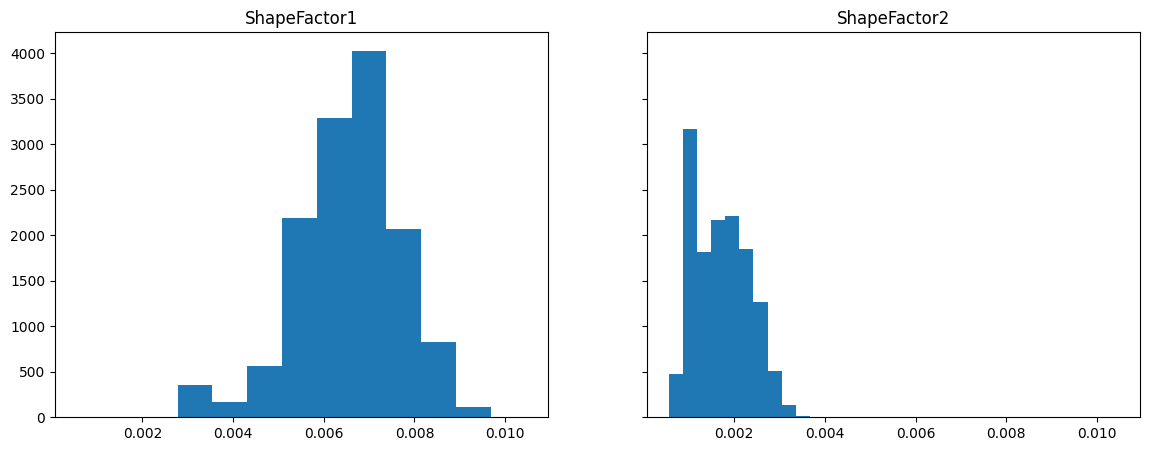

In [17]:
# Order 0.001
ncols = 2
_, axes = plt.subplots(1, ncols=ncols, figsize=(14, 5), sharey=True, sharex=True)

for attribute, i in zip(order_p001, range(ncols)):
    axes[i].hist(df2[attribute])
    axes[i].set_title(attribute)

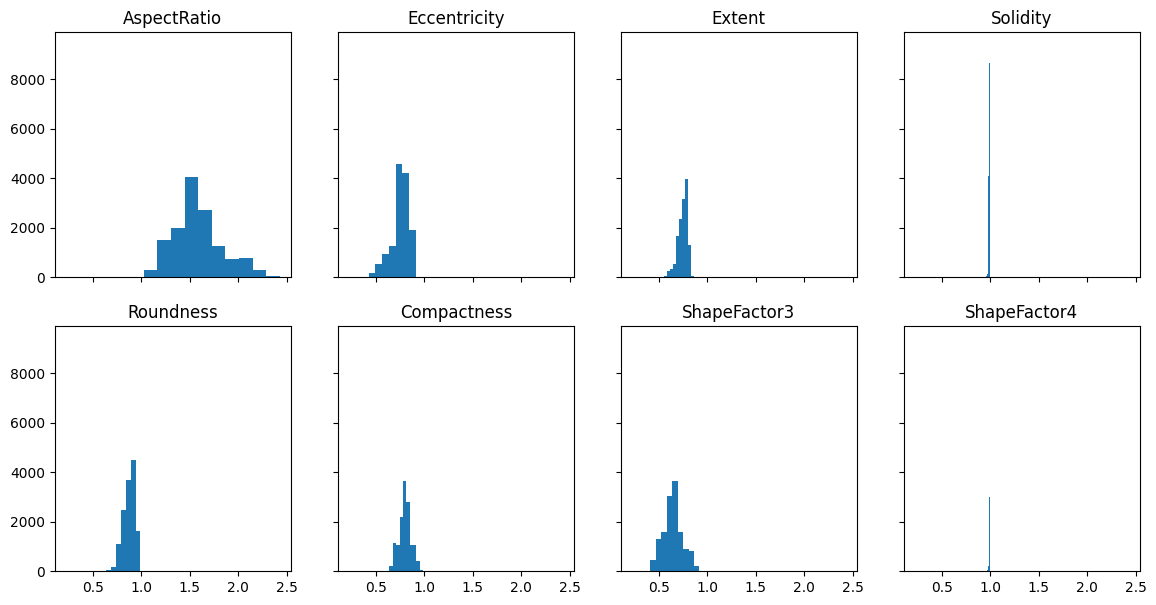

In [18]:
# Order 1
ncols = 4
_, axes = plt.subplots(2, ncols=ncols, figsize=(14, 7), sharey=True, sharex=True)
# fig.sup

for i in range(2):
  for j in range(ncols):
    attribute = order1[ncols * i + j]
    axes[i][j].hist(df2[attribute])
    axes[i][j].set_title(attribute)

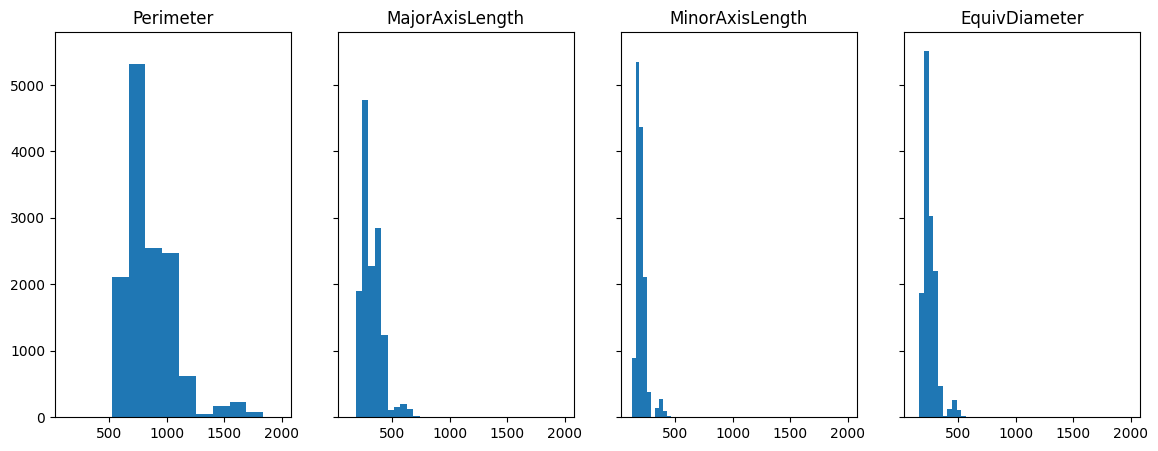

In [19]:
# Order 100
ncols = 4
_, axes = plt.subplots(1, ncols=ncols, figsize=(14, 5), sharey=True, sharex=True)

for attribute, i in zip(order100, range(ncols)):
    axes[i].hist(df2[attribute])
    axes[i].set_title(attribute)

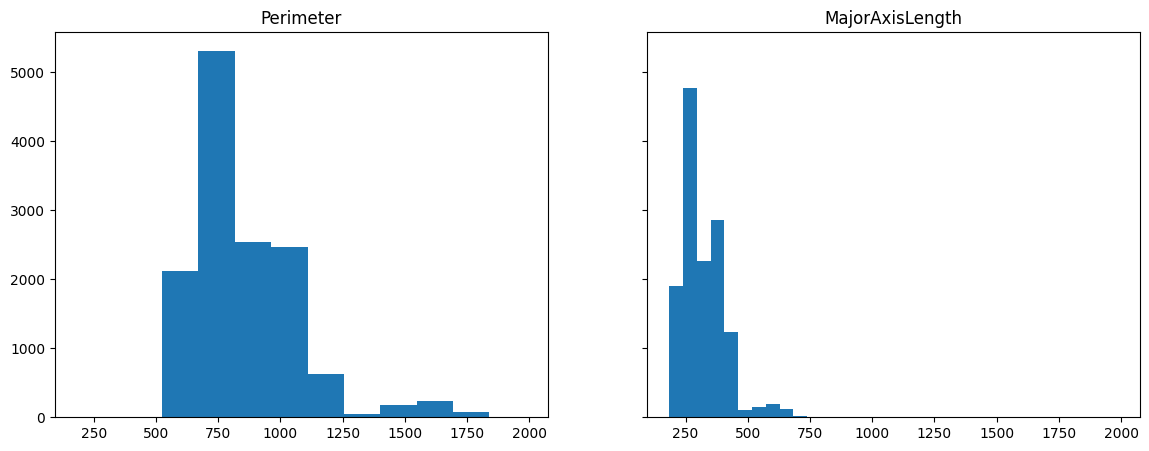

In [20]:
# Order 1000
ncols = 2
_, axes = plt.subplots(1, ncols=ncols, figsize=(14, 5), sharey=True, sharex=True)

for attribute, i in zip(order100, range(ncols)):
    axes[i].hist(df2[attribute])
    axes[i].set_title(attribute)

### 2. O que pode-se dizer a respeito do balanceamento do atributo-alvo?
Considerando o dataset balanceado se não houver mais de 10% de diferença no quantitativo das classes nele presentes.

In [21]:
df3 = dry_bean.data.targets
df3.value_counts(normalize=True)

,proportion
Class,
DERMASON,0.260525
SIRA,0.193667
SEKER,0.148924
HOROZ,0.141650
CALI,0.119756
BARBUNYA,0.097127
BOMBAY,0.038351


O dataset não é balanceado: há bem mais Dermason e Sira que as demais classes

### 3. Que tipo de tarefa de Aprendizado de Máquina é sugestiva para este problema?
Aprendizado supervisionado, especificamente classificação.  

#### 3.1 Apresente métricas de desempenho compatíveis para a avaliação do problema (liste-as textualmente)
Métricas:


*   Acurácia Balanceada: Lida melhor com desbalanceamento de dados
*   F1, Precisão e Recall Macros: calcula a média das pontuações dessas métricas calculadas separadamente para cada classe.
*   G-Score: Útil para classes desbalanceadas, mas não há suporte nativo no sklearn

#### 3.2 Escolha uma das métricas apresentadas para ser utilizada como referência pela equipe
A métrica escolhida como referência é o F1 Score Macro.